# How wide must the corridor be?

In 03, 27 of the 66 High-High patches (res 9) reached the outer edge of the 2 km
band, and they held 85% of the High-High area. A patch cut off by the band edge has
an unknown shape, and clipping a round town to a strip along the road makes it look
*elongated along the road*, which is exactly what a ribbon looks like. So before
classifying patches by shape, the band must be wide enough that patches end inside
it.

Test: widen the band (2, 3, 5, 8 km either side of QL18), redo the LISA each time on
a **coarse grid (H3 res 8, ~0.74 km²)**, and track how much High-High area still
touches the band edge. The width to use is where that share stops falling. Res 8 is
coarse on purpose: cheap, and enough to see towns; ribbon detail is for later.

Still nothing masked (road surface, urban wards), as in 03.

**Caveat for reading the results:** LISA compares each hex with the band's own
mean. Widening the band adds mostly rural hexes, which lowers that mean, so more
hexes count as "High". The High-High set itself changes with width, not just its
truncation.

In [1]:
from typing import Final

import esda
import geopandas as gpd
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from splot.esda import lisa_cluster

from desakota.crs import CRS_UTM, CRS_WGS84
from desakota.hexgrid import build_hex_grid
from desakota.landcover import (
    compute_built_frac_for_tessellation,
    fetch_landcover,
    get_landcover_legend,
)
from desakota.paths import DataLayout
from desakota.stac import create_client, get_bbox_from_aoi, get_collection, search_items

WIDTHS_M: Final = (2_000, 3_000, 5_000, 8_000)  # band half-width, either side of QL18
RESOLUTION: Final = 8
P_LISA: Final = 0.05
RIM_M: Final = 100  # a patch "reaches the edge" if it comes within this of the band's outer limit
TIME_RANGE: Final = '2023-01-02/2023-12-31'
BUILT_AREA_LABEL: Final = 'Built area'
WATER_LABEL: Final = 'Water'

layout = DataLayout.from_env().ensure()
route_ways = gpd.read_file(layout.processed / 'highways_ql18.gpkg')  # EPSG:32648, from 01
route_line = route_ways.union_all()
assert route_ways.crs == CRS_UTM

## 1. Land within 8 km of QL18

The band is clipped to land so the sea and China don't count as "edge". The corridor
communes from 01 only reach 2 km, so land comes from **all** GADM communes within
the widest band.

2000    1071
3000    1567
5000    2504
8000    3795
Name: area_km2, dtype: int64

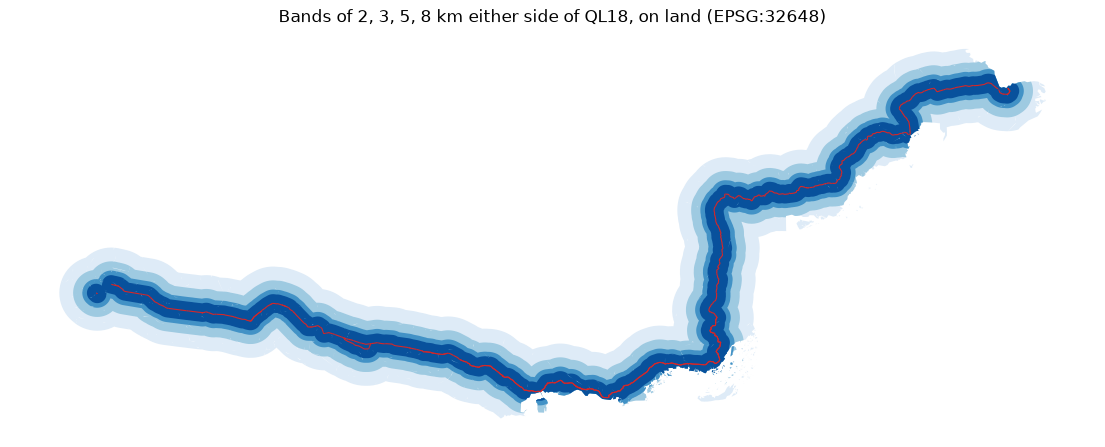

In [2]:
gadm_communes_wgs84 = gpd.read_file(layout.raw / 'gadm41_VNM_3.json')
gadm_communes = gadm_communes_wgs84[['GID_3', 'geometry']].to_crs(CRS_UTM)
max_width_m = max(WIDTHS_M)
land = gadm_communes[gadm_communes.dwithin(route_line, max_width_m)].union_all()
footprints = {width: route_line.buffer(width).intersection(land) for width in WIDTHS_M}

ax = gpd.GeoSeries([footprints[w] for w in reversed(WIDTHS_M)], crs=CRS_UTM).plot(
    color=['#deebf7', '#9ecae1', '#4292c6', '#08519c'], figsize=(14, 6)
)
route_ways.plot(ax=ax, color='#d62728', linewidth=0.8)
ax.set_title('Bands of 2, 3, 5, 8 km either side of QL18, on land (EPSG:32648)')
ax.set_axis_off()
pd.Series({w: round(f.area / 1e6) for w, f in footprints.items()}, name='area_km2')

## 2. Land cover for the widest band

The clip from 01 covers only the 2 km communes' bounding box, so a wider window is
read from the same 2023 tile (48Q) and cached under `raw/lulc` next to it.

In [3]:
client = create_client()
collection = get_collection(client, '10M_ANNUAL_LANDUSE')
legend = get_landcover_legend(collection)
widest = gpd.GeoDataFrame(geometry=[footprints[max_width_m]], crs=CRS_UTM)
items = search_items(
    client, collection, bbox=get_bbox_from_aoi(widest.to_crs(CRS_WGS84)), datetime=TIME_RANGE
).items()
lulc_item = next(item for item in items if item.id.startswith('48Q'))
lulc_path = fetch_landcover(widest, lulc_item, cache_dir=layout.raw / 'lulc')  # first run downloads
lulc_path.name

'lulc_48Q-2023_fa4b43a451f3.tif'

## 3. One coarse grid and one LISA per width

In [4]:
def build_queen_weights(units: gpd.GeoDataFrame) -> libpysal.weights.W:
    """Queen contiguity, islands attached by KNN-1, row-standardised."""
    w_queen = libpysal.weights.Queen.from_dataframe(units, use_index=False, silence_warnings=True)
    if w_queen.islands:
        w_knn1 = libpysal.weights.KNN.from_dataframe(units, k=1, use_index=False)
        w_queen = libpysal.weights.attach_islands(w_queen, w_knn1)
    w_queen.transform = 'r'
    return w_queen


hex_grids: dict[int, gpd.GeoDataFrame] = {}
lisas: dict[int, esda.Moran_Local] = {}
for width in WIDTHS_M:
    grid = build_hex_grid(footprints[width], crs=CRS_UTM, resolution=RESOLUTION)
    grid['built_frac'] = compute_built_frac_for_tessellation(
        grid, lulc_path, legend, built_area_label=BUILT_AREA_LABEL, water_label=WATER_LABEL
    )
    grid = grid.dropna(subset=['built_frac']).reset_index(drop=True)
    w_queen = build_queen_weights(grid)
    lisas[width] = esda.Moran_Local(
        grid['built_frac'], w_queen, permutations=999, seed=42, n_jobs=1
    )
    grid['is_hh'] = (lisas[width].q == 1) & (lisas[width].p_sim < P_LISA)
    hex_grids[width] = grid
    print(f'{width / 1000:.0f} km: {len(grid)} hexes, {grid["is_hh"].sum()} High-High')

/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 442 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


2 km: 1688 hexes, 310 High-High


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 532 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/util.py:1343: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  return W(neighbors, weights, id_order=w.id_order, **kwargs)


3 km: 2294 hexes, 426 High-High


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 696 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/util.py:1343: UserWarning: The weights matrix is not fully connected: 
 There are 7 disconnected components.
  return W(neighbors, weights, id_order=w.id_order, **kwargs)


5 km: 3416 hexes, 584 High-High


/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 947 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
/mnt/c/Users/ADMIN/Desktop/projects/ai_tools/ntl_analysis/.venv/lib/python3.14/site-packages/libpysal/weights/util.py:1343: UserWarning: The weights matrix is not fully connected: 
 There are 21 disconnected components.
  return W(neighbors, weights, id_order=w.id_order, **kwargs)


8 km: 5007 hexes, 830 High-High


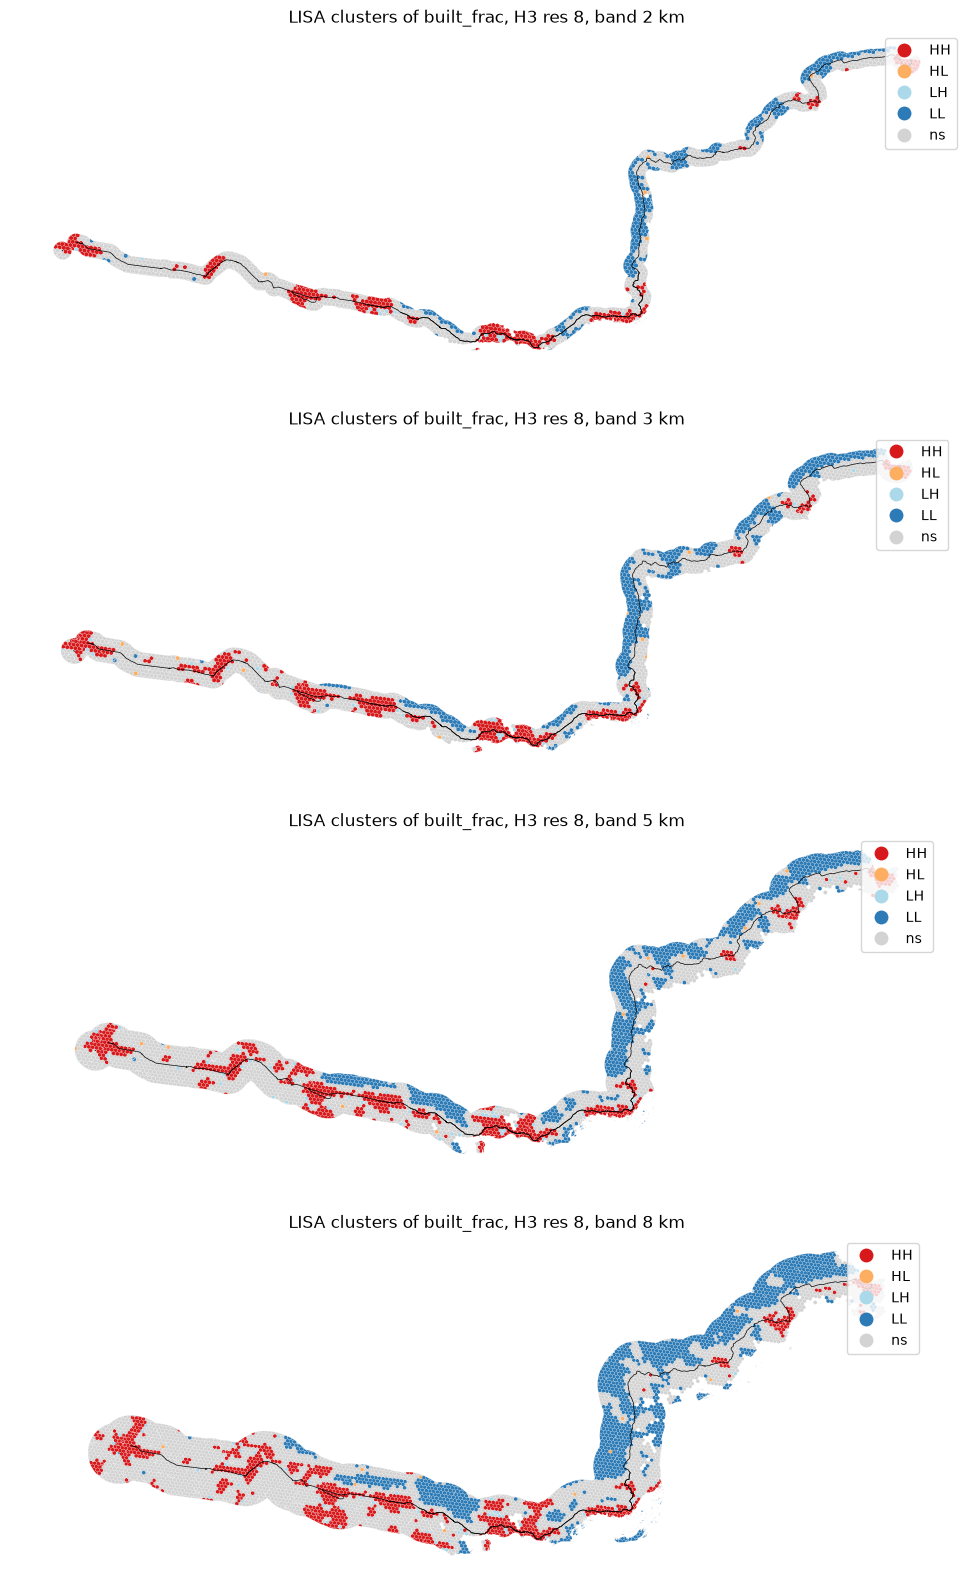

In [5]:
fig, axes = plt.subplots(len(WIDTHS_M), 1, figsize=(14, 5 * len(WIDTHS_M)))
for ax, width in zip(axes, WIDTHS_M, strict=True):
    lisa_cluster(lisas[width], hex_grids[width], p=P_LISA, ax=ax)
    route_ways.plot(ax=ax, color='black', linewidth=0.5)
    ax.set_title(f'LISA clusters of built_frac, H3 res {RESOLUTION}, band {width / 1000:.0f} km')

## 4. Patches and the band edge

Adjacent member hexes are merged into patches with `desakota.patches.detect_patches`.
Two definitions of "member" are compared:

- **LISA:** High-High at p < 0.05, as above. Relative to the band's own mean, so the
  set moves as the band widens.
- **Threshold (option 1):** `built_frac >= BUILT_THRESHOLD`. The same rule at every
  width, so changes across widths are truncation only.

For each patch:
- **reaches_edge:** it comes within `RIM_M` of the band's outer limit (distance
  `width` from QL18). Coast and border are not that limit, so they don't count.
- **elongation:** long ÷ short side of the *equivalent rectangle* (same area and
  perimeter) of the patch's **alpha shape** (Edelsbrunner et al. 1983), drawn
  through its hexagons' vertices with radius `ALPHA_RADIUS_M` (1.5 hexagon edges).
  The alpha shape smooths the zigzag hexagon boundary, which would otherwise
  inflate the perimeter; the equivalent rectangle keeps a ribbon long even where it
  bends with the road, where a minimum rotated rectangle turns it nearly square.

In [6]:
import h3

from desakota.patches import detect_patches

BUILT_THRESHOLD: Final = 0.5
ALPHA_RADIUS_M: Final = 1.5 * h3.average_hexagon_edge_length(RESOLUTION, 'm')


EDGE_COLOUR: Final = '#c51b7d'  # magenta: patch still reaches the band edge


def draw_patch_outlines(ax: plt.Axes, patches: gpd.GeoDataFrame) -> None:
    """Patch boundaries (black; magenta if reaching the band edge) and alpha outlines (dashed)."""
    gpd.GeoSeries(patches['outline']).boundary.plot(
        ax=ax, color='#525252', linewidth=0.6, linestyle='--'
    )
    patches.boundary.plot(ax=ax, color='black', linewidth=0.5)
    if 'reaches_edge' in patches.columns:
        patches[patches['reaches_edge']].boundary.plot(ax=ax, color=EDGE_COLOUR, linewidth=1.5)


def add_reaches_edge(patches: gpd.GeoDataFrame, width_m: float) -> gpd.GeoDataFrame:
    """Copy of `patches` flagging those within RIM_M of the band's outer limit."""
    rim = route_line.buffer(width_m).difference(route_line.buffer(width_m - RIM_M))
    return patches.assign(reaches_edge=patches.intersects(rim))


patches_by_rule: dict[str, dict[int, gpd.GeoDataFrame]] = {'lisa_hh': {}, 'threshold': {}}
for width in WIDTHS_M:
    grid = hex_grids[width]
    members = {'lisa_hh': grid['is_hh'], 'threshold': grid['built_frac'] >= BUILT_THRESHOLD}
    for rule, is_member in members.items():
        patches = detect_patches(grid, is_member, alpha_radius_m=ALPHA_RADIUS_M)
        patches_by_rule[rule][width] = add_reaches_edge(patches, width)


def summarise(patches: gpd.GeoDataFrame) -> dict[str, float]:
    at_edge = patches['reaches_edge']
    return {
        'n_patches': len(patches),
        'n_reaching_edge': int(at_edge.sum()),
        'area_reaching_edge_frac': round(
            patches.loc[at_edge, 'area_km2'].sum() / patches['area_km2'].sum(), 3
        ),
        'elongation_inside': round(patches.loc[~at_edge, 'elongation'].median(), 2),
        'elongation_at_edge': round(patches.loc[at_edge, 'elongation'].median(), 2),
    }


summary = pd.DataFrame(
    [
        {'rule': rule, 'band_km': width / 1000, **summarise(patches)}
        for rule, by_width in patches_by_rule.items()
        for width, patches in by_width.items()
    ]
)
summary

,rule,band_km,n_patches,n_reaching_edge,area_reaching_edge_frac,elongation_inside,elongation_at_edge
0,lisa_hh,2.0,20,12,0.811,1.0,2.01
1,lisa_hh,3.0,28,14,0.763,1.0,2.56
2,lisa_hh,5.0,39,14,0.529,1.0,2.75
3,lisa_hh,8.0,53,19,0.614,1.0,2.41
4,threshold,2.0,56,45,0.966,1.0,3.55
5,threshold,3.0,75,47,0.923,1.0,2.98
6,threshold,5.0,108,47,0.732,1.0,3.73
7,threshold,8.0,139,39,0.543,1.0,2.52


Text(0.5, 1.0, 'Truncation of patches, H3 res 8')

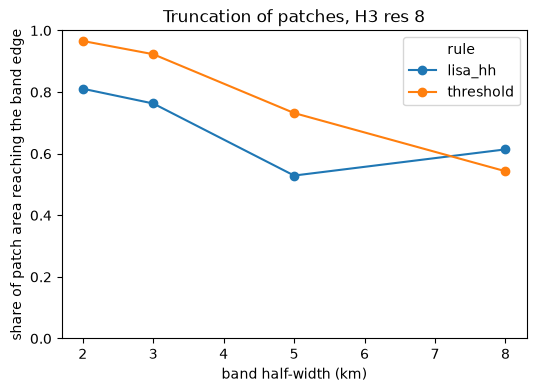

In [7]:
ax = summary.pivot(index='band_km', columns='rule', values='area_reaching_edge_frac').plot(
    marker='o', figsize=(6, 4)
)
ax.set_xlabel('band half-width (km)')
ax.set_ylabel('share of patch area reaching the band edge')
ax.set_ylim(0, 1)
ax.set_title(f'Truncation of patches, H3 res {RESOLUTION}')

**Does the alpha shape change the answer?** The same threshold patches at the
widest band, scored both ways. Patches where the two disagree most are the bent
ones.

,patch_id,n_cells,area_km2,elongation,reaches_edge,elongation_rotated_rect
0,0,141,99.94,16.56,True,2.12
1,1,126,95.68,12.89,True,1.47
2,2,127,95.16,6.12,True,1.30
3,3,92,73.49,12.54,False,1.59
4,4,90,71.60,10.82,False,2.08
5,5,80,58.03,14.44,False,2.34
6,6,65,49.47,11.58,True,1.40
7,7,44,33.95,6.24,True,2.11
8,8,38,30.25,6.49,False,1.08
9,9,39,29.05,4.72,False,1.01


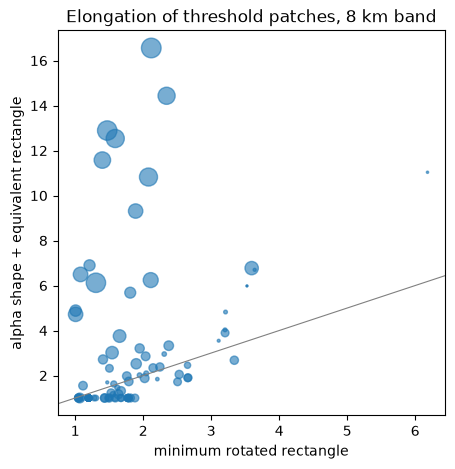

In [8]:
def rotated_rectangle_elongation(geometry: shapely.Geometry) -> float:
    x, y = shapely.minimum_rotated_rectangle(geometry).exterior.coords.xy
    sides_m = np.hypot(np.diff(x[:3]), np.diff(y[:3]))
    return float(sides_m.max() / max(sides_m.min(), 1.0))


compared = patches_by_rule['threshold'][max(WIDTHS_M)].assign(
    elongation_rotated_rect=lambda frame: frame.geometry.map(rotated_rectangle_elongation)
)
ax = compared.plot.scatter(
    x='elongation_rotated_rect',
    y='elongation',
    s=np.sqrt(compared['area_km2']) * 20,
    alpha=0.6,
    figsize=(5, 5),
)
ax.axline((1, 1), slope=1, color='grey', linewidth=0.8)
ax.set_xlabel('minimum rotated rectangle')
ax.set_ylabel('alpha shape + equivalent rectangle')
ax.set_title('Elongation of threshold patches, 8 km band')
compared.drop(columns=['geometry', 'outline']).sort_values('area_km2', ascending=False).head(
    10
).round(2)

Patches at the widest band for both rules, coloured by elongation. Black line:
the patch boundary (union of its hexes); dashed: its alpha outline, the shape the
elongation is measured on; magenta: patches still reaching the band edge (also drawn
around their holes).

The alpha outline fills every hole and inlet narrower than 2 × `ALPHA_RADIUS_M`
(~1.6 km, about two hexes), however deep. That is where the dashed line cuts
straight across unbuilt land: on the largest patches it adds 19-44% area and
reaches up to 3.4 km into long, narrow gaps between branches.

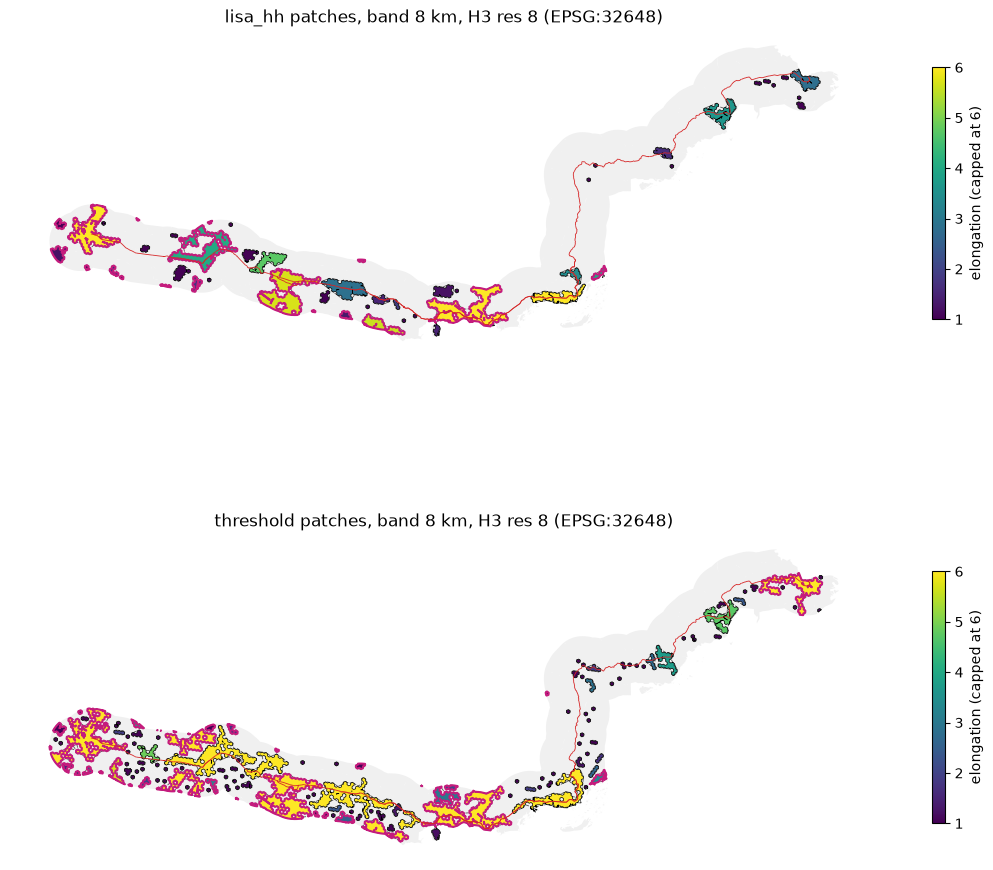

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(14, 12))
for ax, rule in zip(axes, patches_by_rule, strict=True):
    patches = patches_by_rule[rule][max(WIDTHS_M)]
    gpd.GeoSeries([footprints[max(WIDTHS_M)]], crs=CRS_UTM).plot(ax=ax, color='#f0f0f0')
    patches.plot(
        ax=ax,
        column='elongation',
        cmap='viridis',
        legend=True,
        vmin=1,
        vmax=6,
        legend_kwds={'shrink': 0.6, 'label': 'elongation (capped at 6)'},
    )
    draw_patch_outlines(ax, patches)
    route_ways.plot(ax=ax, color='#d62728', linewidth=0.6)
    ax.set_title(
        f'{rule} patches, band {max(WIDTHS_M) / 1000:.0f} km, H3 res {RESOLUTION} (EPSG:32648)'
    )
    ax.set_axis_off()

## 5. Relating patches to QL18

Shape alone can't separate one ribbon along QL18 from a branching web of strips
(both have long, ragged outlines, see the scatter above). So each patch is related
to the road with `desakota.patches.add_road_measures`:

- **road_cover_m:** length of QL18 inside the patch, as area(patch ∩ road buffered
  250 m) / 500 m (Steiner's formula), so divided sections mapped as two one-way
  ways are not counted twice.
- **near_road_frac:** share of the patch's area within `NEAR_M` of QL18. `NEAR_M` is
  about one res-8 cell, so a one-cell strip sitting on the road scores ~1.

Provisional classes (thresholds are a first guess, to be checked on imagery like
Verbeek's expert panel did):
- **ribbon candidate:** `road_cover_m >= MIN_COVER_M` and `near_road_frac >= MIN_NEAR_FRAC`
- **road-touching:** lines some QL18 but mostly lies further away (towns, webs)
- **off-road:** doesn't line QL18 at all

In [10]:
from desakota.patches import add_road_measures

NEAR_M: Final = 1_000
MIN_COVER_M: Final = 2_000
MIN_NEAR_FRAC: Final = 0.6
CLASS_COLOURS: Final = {
    'ribbon candidate': '#d62728',
    'road-touching': '#ff7f0e',
    'off-road': '#7f7f7f',
}


def classify(patches: gpd.GeoDataFrame) -> pd.Series:
    is_ribbon = (patches['road_cover_m'] >= MIN_COVER_M) & (
        patches['near_road_frac'] >= MIN_NEAR_FRAC
    )
    is_touching = patches['road_cover_m'] > 0
    return pd.Series(
        np.select([is_ribbon, is_touching], ['ribbon candidate', 'road-touching'], 'off-road'),
        index=patches.index,
        name='patch_class',
    )


classified = {
    width: add_road_measures(patches, route_line, near_m=NEAR_M).pipe(
        lambda frame: frame.assign(patch_class=classify(frame))
    )
    for width, patches in patches_by_rule['threshold'].items()
}

pd.DataFrame(
    {
        f'{width / 1000:.0f} km': frame.groupby('patch_class')['area_km2'].sum().round(1)
        for width, frame in classified.items()
    }
).rename_axis('patch area (km2) by class')

,2 km,3 km,5 km,8 km
patch area (km2) by class,,,,
off-road,18.5,43.6,114.6,269.7
ribbon candidate,297.7,123.3,62.0,62.0
road-touching,100.8,351.2,507.9,602.5


The area in each class should stop changing once the band is wide enough for
that class: ribbons hug the road, so their area should settle at a narrow band;
road-touching patches keep growing as their far parts come into view.

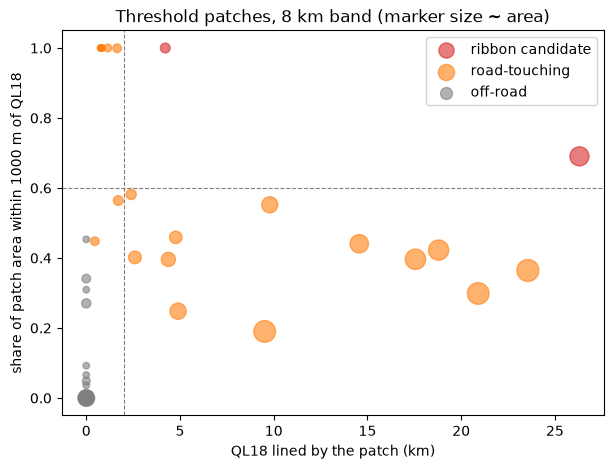

In [11]:
widest = classified[max(WIDTHS_M)]
fig, ax = plt.subplots(figsize=(7, 5))
for name, colour in CLASS_COLOURS.items():
    subset = widest[widest['patch_class'] == name]
    ax.scatter(
        subset['road_cover_m'] / 1000,
        subset['near_road_frac'],
        s=np.sqrt(subset['area_km2']) * 25,
        color=colour,
        alpha=0.6,
        label=name,
    )
ax.axvline(MIN_COVER_M / 1000, color='grey', linewidth=0.8, linestyle='--')
ax.axhline(MIN_NEAR_FRAC, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('QL18 lined by the patch (km)')
ax.set_ylabel(f'share of patch area within {NEAR_M} m of QL18')
ax.set_title('Threshold patches, 8 km band (marker size ~ area)')
ax.legend()

,patch_id,n_cells,area_km2,elongation,reaches_edge,road_cover_m,near_road_frac,patch_class
5,5,80,58.03,14.44,False,26309.32,0.69,ribbon candidate
0,0,141,99.94,16.56,True,23558.34,0.36,road-touching
2,2,127,95.16,6.12,True,20908.62,0.30,road-touching
4,4,90,71.60,10.82,False,18796.82,0.42,road-touching
3,3,92,73.49,12.54,False,17560.65,0.40,road-touching
6,6,65,49.47,11.58,True,14561.25,0.44,road-touching
9,9,39,29.05,4.72,False,9788.76,0.55,road-touching
1,1,126,95.68,12.89,True,9516.47,0.19,road-touching
8,8,38,30.25,6.49,False,4897.27,0.25,road-touching
15,15,13,10.37,6.90,False,4774.08,0.46,road-touching


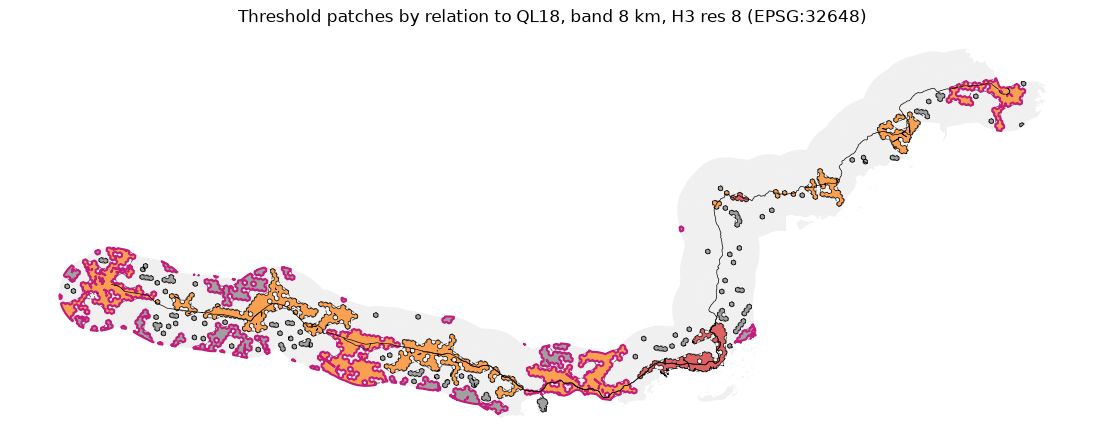

In [12]:
ax = gpd.GeoSeries([footprints[max(WIDTHS_M)]], crs=CRS_UTM).plot(color='#f0f0f0', figsize=(14, 6))
for name, colour in CLASS_COLOURS.items():
    subset = widest[widest['patch_class'] == name]
    if not subset.empty:
        subset.plot(ax=ax, color=colour, alpha=0.7, label=name)
draw_patch_outlines(ax, widest)
route_ways.plot(ax=ax, color='black', linewidth=0.5)
ax.set_title(
    f'Threshold patches by relation to QL18, band {max(WIDTHS_M) / 1000:.0f} km, H3 res {RESOLUTION} (EPSG:32648)'
)
ax.set_axis_off()
widest.loc[widest['patch_class'] != 'off-road'].drop(columns=['geometry', 'outline']).sort_values(
    'road_cover_m', ascending=False
).round(2)

Zoom on the Chí Linh – Đông Triều stretch, where the large ribbon candidate
meets the delta's road-touching patches. Grey: all res-8 hexes of the 8 km band.

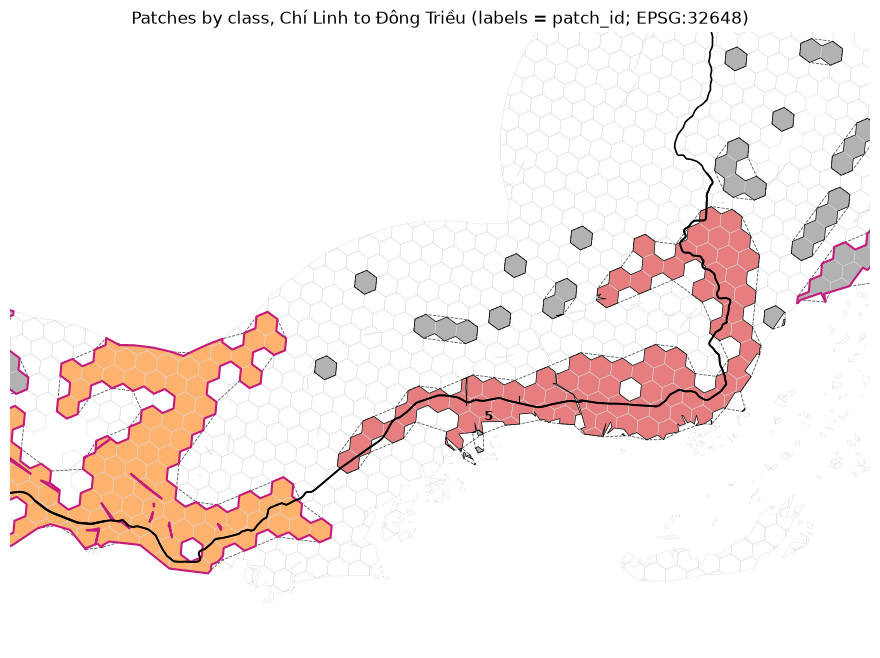

In [13]:
ribbon = widest[widest['patch_class'] == 'ribbon candidate'].iloc[0]  # largest, sorted by area
minx, miny, maxx, maxy = ribbon.geometry.bounds
zoom_xlim, zoom_ylim = (minx - 15_000, maxx + 5_000), (miny - 8_000, maxy + 8_000)

fig, ax = plt.subplots(figsize=(12, 8))
hex_grids[max(WIDTHS_M)].boundary.plot(ax=ax, color='#d9d9d9', linewidth=0.3)
for name, colour in CLASS_COLOURS.items():
    subset = widest[widest['patch_class'] == name]
    if not subset.empty:
        subset.plot(ax=ax, color=colour, alpha=0.6)
draw_patch_outlines(ax, widest)
route_ways.plot(ax=ax, color='black', linewidth=1.2)
for _, patch in widest.cx[zoom_xlim[0] : zoom_xlim[1], zoom_ylim[0] : zoom_ylim[1]].iterrows():
    if patch['patch_class'] != 'off-road':
        point = patch.geometry.representative_point()
        ax.annotate(
            int(patch['patch_id']), (point.x, point.y), ha='center', fontsize=9, weight='bold'
        )
ax.set_xlim(zoom_xlim)
ax.set_ylim(zoom_ylim)
ax.set_title('Patches by class, Chí Linh to Đông Triều (labels = patch_id; EPSG:32648)')
ax.set_axis_off()